# Comparing Effective Radius vs Velocity Dispersion
We'll look at one of the fundamental plane relations, effective radius vs velocity dispersion.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [27]:
# By now standard code that merges the three excel data sheets.
morph = pd.read_csv('SAMI_Visual_Morphology/samiDR3VisualMorphology.csv')
cat = pd.read_csv('SAMI_Input_Cat_Cluster/samiDR3InputCatClusters.csv')
kin = pd.read_csv('SAMI_Kinematics/samiDR3StelKin.csv')

morphcat = pd.merge(morph, cat, on='catid', how='inner')
df = pd.merge(morphcat, kin, on='catid', how='inner')
print('Final Data Set', len(df))

Final Data Set 962


In [29]:
# Now, the important headers are:
# -- type 0 or 0.5 from Visual Morphology
# -- r_e for effective radius
# -- sigma_re, sigma_re_err, sigma_3kpc_round, sigma_3kpc_round_err, 
#    sigma_1_4_arcsecond, sigma_1_4_arcsecond_err, sigma_2_arcsecond, sigma_2_arcsecond_err, 
#    sigma_3_arcsecond, sigma_3_arcsecond_err, sigma_4_arcsecond, sigma_4_arcsecond_err.

df = df.dropna(subset = ['type', 'r_e']) # won't drop NaN for different sigma_re just yet.
# This has dropped one 0.0 galaxy and 2 0.5 galaxies -- good!
el_zero = df[df['type'] == 0];
el_half = df[df['type'] == 0.5];

print(f"We have {len(el_zero)} type 0.0 galaxies and {len(el_half)} type 0.5 galaxies.");

We have 151 type 0.0 galaxies and 126 type 0.5 galaxies.


In [30]:
el_zero_re = pd.to_numeric(el_zero['r_e'], errors='coerce');
el_half_re = pd.to_numeric(el_half['r_e'], errors='coerce');

el_zero_sigma_re = pd.to_numeric(el_zero['sigma_re'], errors='coerce');
el_half_sigma_re = pd.to_numeric(el_half['sigma_re'], errors='coerce');
el_zero_sigma_re_err = pd.to_numeric(el_zero['sigma_re_err'], errors='coerce');
el_half_sigma_re_err = pd.to_numeric(el_half['sigma_re_err'], errors='coerce');

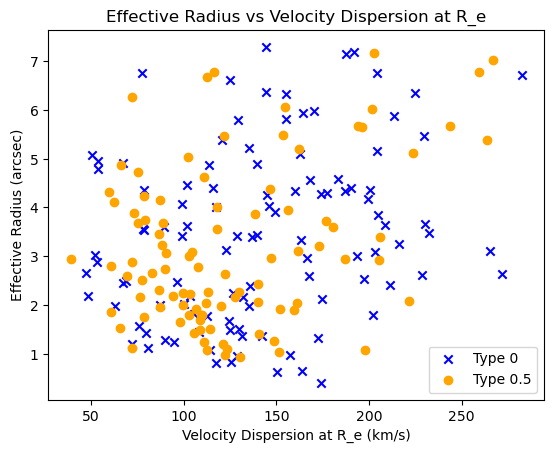

In [42]:
# Time to plot! Let's see... why is there no trend?

plt.scatter(el_zero_sigma_re, el_zero_re, marker='x', color='blue', label='Type 0')
plt.scatter(el_half_sigma_re, el_half_re, marker='o', color='orange', label='Type 0.5');
#plt.errorbar(el_zero_sigma_re, el_zero_re, xerr=el_zero_sigma_re_err, fmt='none', color='blue', label='Type 0', linestyle='none')
#plt.errorbar(el_half_sigma_re, el_half_re, xerr=el_half_sigma_re_err, fmt='none', color='orange', label='Type 0.5', linestyle='none');
plt.title("Effective Radius vs Velocity Dispersion at R_e")
plt.xlabel("Velocity Dispersion at R_e (km/s)")
plt.ylabel("Effective Radius (arcsec)")
plt.legend();
plt.show()